# MSE802 Assessment 2 — Task 4: Machine Learning Quantum Analysis

| Item | Detail |
|---|---|
| Original file | `Quantum_ML_AS2.ipynb` (Lab 10, supplied by the lecturer; called *ML_quantum.ipynb* in the brief) |
| Learning outcomes | LO1, LO2, LO4 |

**Task questions**
1. Analyse the code, especially the **circuit** and the **problem formulation**. What data goes into the circuit, and which part of the code is the input?
2. Run the code, **monitor the output at every iteration**, and plot **iteration vs output** and **iteration vs time**.
3. Modify the code to run **locally without the quantum computer or circuit**, and measure the differences in **efficiency** and **effectiveness**.

### What we changed in the supplied notebook
* `[CHANGED]` removed `from google.colab import files` (not used, and it breaks outside Colab).
* `[ADDED]` one switch (`run_circuit`) chooses where circuits run: **Quokka**, or the **local simulator** if Quokka is offline (always labelled).
* `[ADDED]` the SPSA optimiser now **records the output and the time of every iteration**.
* `[ADDED]` two plots, a test-accuracy check, and two local versions for the comparison:
  * **Local-A, no quantum computer:** the same circuit simulated exactly with NumPy (our own 4-qubit state-vector code).
  * **Local-B, no quantum circuit:** a purely classical model (logistic regression) trained by the same optimiser.

### Running in Google Colab?
Run the next cell first. In Colab it downloads the project from GitHub, installs the packages and moves into this task's folder. In VS Code / Jupyter it does nothing.

In [1]:
# ---------- Google Colab bootstrap (skipped automatically on your own PC) ----------
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/anishnz/quantumcomputing_YB_Anish.git"
REPO_DIR = Path("/content/quantumcomputing_YB_Anish")
TASK_DIR = "Task_4_Quantum_ML"
if "google.colab" in sys.modules and not (Path.cwd().parent / "common").exists():
    if not REPO_DIR.exists():                         # 1. download the project from GitHub
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",   # 2. install quantum packages
                    "cirq-core", "qiskit", "qiskit-aer", "pylatexenc"], check=True)
    os.chdir(REPO_DIR / "Assignment_2_Quantum" / TASK_DIR)     # 3. work inside this task's folder
print("Working folder:", Path.cwd())

Working folder: /home/claude/Assignment_2_Quantum/Task_4_Quantum_ML


## 0. Settings and imports

In [2]:
# the usual imports (original)
import numpy as np                       # arrays and maths
import scipy as sp                       # Nelder-Mead optimiser (original first example)
import scipy.optimize                    # make sure sp.optimize is loaded
import requests                          # HTTP calls to Quokka (inside the helper)
import math, json, time, sys             # utilities; time is used for the iteration timer
from pathlib import Path
import pandas as pd                      # [ADDED] result tables
import matplotlib.pyplot as plt          # plots
# from google.colab import files         # [CHANGED] removed: Colab-only and never used

sys.path.insert(0, str(Path.cwd().parent / "common"))
import quokka_helper as qh               # [ADDED] team helper (Quokka call + labelled fallback)

req_str_qasm = qh.QUOKKA_URL             # current Quokka address (same as the original notebook)

SHOTS = 1000          # [ADDED] shots per circuit (the original used 100 in training; the group agreed on 1000)
MAXITER = 100         # SPSA iterations (same as the original)
SEED = 2026           # [ADDED] fixed random seed so every run of this notebook is repeatable
np.random.seed(SEED)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

STATUS = qh.quokka_status()              # check once, so we do not wait for a timeout on every call
USE_QUOKKA = STATUS == "online"
SOURCE = qh.SOURCE_QUOKKA if USE_QUOKKA else qh.SOURCE_LOCAL
print("Quokka status:", STATUS)
print("Quantum circuits will run on:", SOURCE)

Quokka status: offline (Quokka endpoint is offline (HTTP 404, ERR_NGROK_3200))
Quantum circuits will run on: LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable


In [3]:
def run_circuit(qasm, count=SHOTS):
    """[ADDED] Run one QASM circuit and return the list of shots ([c0], [c0], ...).

    Uses Quokka when it is online (exactly like the original requests.post call),
    otherwise the same QASM on the local Qiskit Aer simulator (labelled in SOURCE).
    """
    if USE_QUOKKA:
        data = qh.run_on_quokka(qasm, count)             # POST {'script': qasm, 'count': count}
        return list(data["result"].values())[0]          # first classical register
    return qh.run_locally(qasm, count)

CIRCUIT_CALLS = {"n": 0}                                 # [ADDED] counts how many circuits were executed

## 1. Hello, quantum learner (original warm-up)

One qubit, one parameter: $R_x(\theta)$ then measure. The model output is the **fraction of 1s**, $\hat p(\theta) \approx \sin^2(\theta/2)$. The goal is to output 1, so the loss is $(1-\hat p)^2$. The minimum is at $\theta=\pi$.

In [4]:
def qubit_learner(angle, count=SHOTS):
    qasm = """
    OPENQASM 2.0;
    include "qelib1.inc";
    qreg q[1];
    creg result[1];
    rx({}) q[0];
    measure q[0] -> result[0];
    """.format(np.atleast_1d(angle)[0])                 # rotate by the trial angle, then measure
    CIRCUIT_CALLS["n"] += 1
    return np.mean(run_circuit(qasm, count))            # fraction of shots that gave 1

def objective_function(angle, bit=1):
    error = bit - qubit_learner(angle)                  # how far the output is from the target bit
    return np.abs(error) ** 2                           # squared error

warm = sp.optimize.minimize(objective_function, x0=np.random.randn(),
                            method='Nelder-Mead', options={'maxiter': 10})
print(warm)
print(f"Learned angle = {warm.x[0]:.3f} rad (ideal pi = {math.pi:.3f})")

       message: Maximum number of iterations has been exceeded.
       success: False
        status: 2
           fun: 0.8723559999999999
             x: [-4.695e-01]
           nit: 10
          nfev: 25
 final_simplex: (array([[-4.695e-01],
                       [-4.694e-01]]), array([ 8.724e-01,  8.911e-01]))
Learned angle = -0.469 rad (ideal pi = 3.142)


## 2. The problem: bars versus stripes

Each image is **2 × 2 = 4 pixels**, each pixel 0 or 1. The code calls the label-0 class **stripes** and the label-1 class **bars**; when the 4 pixels are drawn row by row, label-0 images are vertical lines and label-1 images are horizontal lines (the names are only labels; what matters is that the two classes are the two line directions). The all-black and all-white images are removed because they belong to both classes. That leaves **4 images**.

**Important property:** the two images in each class are exact opposites ([1,0,1,0] and [0,1,0,1]; [1,1,0,0] and [0,0,1,1]). Adding the two images of either class gives [1,1,1,1], so **no straight line (linear model) can separate the classes** — it is an XOR-type problem.

dataset (one image per row):
 [[1. 0. 1. 0.]
 [0. 1. 0. 1.]
 [1. 1. 0. 0.]
 [0. 0. 1. 1.]]
labels: [0. 0. 1. 1.]  parameters: 6


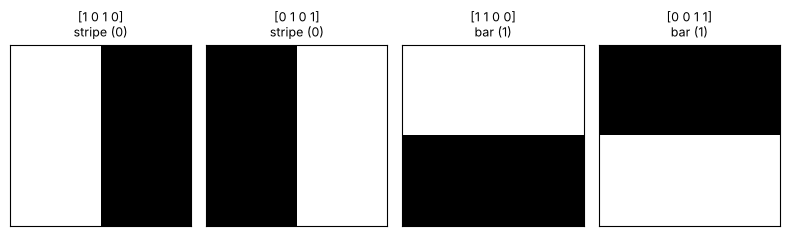

In [5]:
def generate_binary_code(bit_length):
    """All 2**bit_length binary numbers, one per row (lowest bit in column 0)."""
    bit_combinations = np.zeros((int(2**bit_length), bit_length))
    for number in range(int(2**bit_length)):
        dividend = number
        bit_index = 0
        while dividend != 0:
            bit_combinations[number, bit_index] = np.remainder(dividend, 2)   # next binary digit
            dividend = np.floor_divide(dividend, 2)
            bit_index += 1
    return bit_combinations

def generate_data(length):
    stripes = generate_binary_code(length)                     # one value per ROW
    stripes = np.repeat(stripes, length, 0)
    stripes = stripes.reshape(2 ** length, length * length)    # rows repeated -> horizontal stripes

    bars = generate_binary_code(length)                        # one value per COLUMN
    bars = bars.reshape(2 ** length * length, 1)
    bars = np.repeat(bars, length, 1)
    bars = bars.reshape(2 ** length, length * length)          # columns repeated -> vertical bars

    # drop the first (all 0) and last (all 1) pattern of each kind
    return np.vstack((stripes[1:stripes.shape[0]-1], bars[1:bars.shape[0]-1]))

length = 2                                                     # image is length x length pixels
dataset = generate_data(length)                                # 4 images x 4 pixels
labels = np.concatenate((np.zeros(int(2**length-2)), np.ones(int(2**length-2))))   # 0 = stripe, 1 = bar
n_parameters = int(2*(length**2-1))                            # 3 blocks x 2 angles = 6 trainable angles

print("dataset (one image per row):\n", dataset)
print("labels:", labels, " parameters:", n_parameters)

fig, axes = plt.subplots(1, len(dataset), figsize=(8, 2.4))
for ax, img, lab in zip(axes, dataset, labels):
    ax.imshow(img.reshape(length, length), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{img.astype(int)}\n{'bar (1)' if lab else 'stripe (0)'}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(RESULTS / "task4_dataset.png", dpi=200); plt.show()

In [6]:
# Select 75% of the entries for training (original logic, now with a fixed seed)
rng = np.random.default_rng(SEED)
selected_indices = rng.choice(dataset.shape[0], int(dataset.shape[0] * 0.75), replace=False)
all_indices = np.arange(dataset.shape[0])
unselected_indices = np.setdiff1d(all_indices, selected_indices)

training = dataset[selected_indices];   training_labels = labels[selected_indices]
test = dataset[unselected_indices];     test_labels = labels[unselected_indices]
print("training images:", selected_indices, "test image:", unselected_indices)

training images: [3 1 0] test image: [2]


## 3. The circuit — where does the data go in?

**Input (data encoding).** In `create_circuit`, the loop

```python
for i in range(length):
    if data[i] > 0.5:
        qasm += "x q[i];"
```

is the **input part**. Each pixel is one qubit. A white pixel (1) gets an **X gate** (|0⟩→|1⟩); a black pixel (0) stays |0⟩. This is called **basis encoding**: the image *is* the starting basis state, e.g. pixels [1,0,1,0] → $|q_3q_2q_1q_0\rangle = |0101\rangle$.

**Trainable part.** `block(angles, qubits)` applies $R_y(\theta_a)$ and $R_y(\theta_b)$ to two qubits and then a CNOT. `generate_pairs` joins the blocks as a tree, (0,1), (2,3), then (1,3), so information from all four pixels flows into **qubit 3** in only $\log_2 4 = 2$ layers. This is a small *tree tensor network* classifier.

**Output.** Only qubit 3 is measured. The model output is
$$\hat y(\boldsymbol\theta, \mathbf x) = P(q_3 = 1) \approx \frac{\#\text{ shots with } 1}{\text{shots}}.$$

**Problem formulation (loss).** The `objective` is the mean absolute error over the training images:
$$L(\boldsymbol\theta) = \frac{1}{N}\sum_{n=1}^{N}\left|\hat y(\boldsymbol\theta,\mathbf x_n) - y_n\right|$$
A bar should give $\hat y \to 1$ and a stripe $\hat y \to 0$. We classify with $\hat y > 0.5 \Rightarrow$ bar.

In [7]:
def block(angles, qubits):
    """Trainable 2-qubit block: RY on each qubit, then CNOT (entangles the pair)."""
    qasm = """
  ry({}) q[{}];
  ry({}) q[{}];
  cx q[{}], q[{}];
  """.format(angles[0], qubits[0],          # rotation angle for the first qubit
             angles[1], qubits[1],          # rotation angle for the second qubit
             qubits[0], qubits[1])          # CNOT: first qubit controls the second
    return qasm

def generate_pairs(mylist, start, end):
    """Split the qubit range in half again and again; append the pair that joins the halves."""
    if start == end:
        pass                                # one qubit: nothing to join
    else:
        mid = (start + end - 1) // 2
        generate_pairs(mylist, start, mid)  # left half
        generate_pairs(mylist, mid + 1, end)  # right half
        mylist.append((mid, end))           # join the halves -> information moves toward 'end'

def create_circuit(data, angles):
    length = data.shape[0]                  # number of pixels = number of qubits
    qasm = """
    OPENQASM 2.0;
    include "qelib1.inc";
    qreg q[{}];
    creg c[1];
    """.format(length)

    for i in range(length):                 # ---- INPUT: basis encoding of the image ----
        if data[i] > 0.5:
            qasm += """
    x q[{}];
    """.format(i)                           # white pixel -> |1>

    pairs = []
    generate_pairs(pairs, 0, length - 1)    # e.g. [(0,1), (2,3), (1,3)] for 4 qubits

    count = 0
    for (i, j) in pairs:                    # ---- MODEL: one trainable block per pair ----
        qasm += block([angles[count], angles[count + 1]], [i, j])
        count += 2

    qasm += """
  measure q[{}] -> c[0];
  """.format(length - 1)                    # ---- OUTPUT: read only the last qubit ----
    return qasm

pairs = []; generate_pairs(pairs, 0, 3); print("block pairs:", pairs)
print(create_circuit(dataset[0], np.zeros(n_parameters)))   # example with all-zero angles

block pairs: [(0, 1), (2, 3), (1, 3)]

    OPENQASM 2.0;
    include "qelib1.inc";
    qreg q[4];
    creg c[1];
    
    x q[0];
    
    x q[2];
    
  ry(0.0) q[0];
  ry(0.0) q[1];
  cx q[0], q[1];
  
  ry(0.0) q[2];
  ry(0.0) q[3];
  cx q[2], q[3];
  
  ry(0.0) q[1];
  ry(0.0) q[3];
  cx q[1], q[3];
  
  measure q[3] -> c[0];
  


In [8]:
# Draw the circuit for one image with example angles (for the report)
import qiskit.qasm2
example = qiskit.qasm2.loads(create_circuit(dataset[2], np.round(np.linspace(0.3, 1.8, n_parameters), 2)))
fig = example.draw("mpl")
fig.savefig(RESULTS / "task4_circuit.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. The objective function (original) and the quantum predictor

In [9]:
def quantum_predict(x, image, count=SHOTS):
    """[ADDED] y_hat = fraction of 1s on qubit 3 after running the circuit."""
    CIRCUIT_CALLS["n"] += 1
    return np.mean(run_circuit(create_circuit(image, x), count))

def objective(x, dataset, labels, count=SHOTS):
    """Mean |y_hat - label| over a set of images (same formula as the original)."""
    n_data = dataset.shape[0]
    to_return = 0
    for idx in range(n_data):
        to_return += np.abs(quantum_predict(x, dataset[idx], count) - labels[idx])
    return to_return / n_data

## 5. SPSA optimiser with monitoring

SPSA (Spall, 1992) estimates the gradient from only **two** loss evaluations per iteration, whatever the number of parameters, which suits noisy hardware. We added a log: after each update we record the **training loss (output measure)** and the **time the update took**. The monitoring evaluation itself is timed separately, so it does not distort the per-iteration time.

In [10]:
def spsa(func, x0, a=0.1, c=0.01, alpha=0.602, gamma=0.101, maxiter=100, verbose=False, monitor=None):
    """Original SPSA plus [ADDED] per-iteration history: iteration, output, time."""
    k = 0
    x = np.array(x0, dtype=float)
    history = []                                         # [ADDED]
    maxiter = int(maxiter)
    while k < maxiter:
        t0 = time.perf_counter()                         # [ADDED] start timer
        ak = a / (k + 1) ** alpha                        # step size shrinks slowly
        ck = c / (k + 1) ** gamma                        # perturbation size shrinks slowly
        delta = 2 * np.random.randint(0, 2, len(x0)) - 1 # random +1/-1 for every parameter
        xp = x + ck * delta
        xm = x - ck * delta
        grad = (func(xp) - func(xm)) / (2 * ck) * delta  # two evaluations -> full gradient estimate
        x = x - ak * grad                                # move downhill
        step_time = time.perf_counter() - t0             # [ADDED] time for this iteration

        fx = (monitor or func)(x)                        # [ADDED] output measure after the update
        history.append({"iteration": k + 1, "output": fx, "time_s": step_time})
        if verbose and k % max(1, int(0.1 * maxiter)) == 0:
            print(f"Iteration {k}: f = {fx:.4f}   ({step_time:.3f} s)")
        k += 1
    return x, pd.DataFrame(history)

def accuracy(predict, x, images, labels):
    """[ADDED] fraction of images classified correctly (y_hat > 0.5 means bar)."""
    preds = np.array([predict(x, img) for img in images]) > 0.5
    return float(np.mean(preds == labels.astype(bool)))

## 6. Run the quantum version (circuits on Quokka, or the labelled local simulator)

In [11]:
np.random.seed(SEED)
x0 = np.pi * np.random.randn(n_parameters)               # same random start for every version
f_quantum = lambda x: objective(x, training, training_labels, count=SHOTS)

CIRCUIT_CALLS["n"] = 0
t_start = time.perf_counter()
x_quantum, hist_quantum = spsa(f_quantum, x0, a=1, c=0.5, alpha=0.602, gamma=0.101,
                               maxiter=MAXITER, verbose=True)
total_quantum = time.perf_counter() - t_start
calls_quantum = CIRCUIT_CALLS["n"]
hist_quantum.to_csv(RESULTS / "task4_quantum_iterations.csv", index=False)
print(f"\nRan on: {SOURCE}")
print(f"Total time {total_quantum:.1f} s, circuits executed: {calls_quantum}")

Iteration 0: f = 0.5027   (0.635 s)


Iteration 10: f = 0.2897   (0.552 s)


Iteration 20: f = 0.1927   (0.558 s)


Iteration 30: f = 0.0873   (0.592 s)


Iteration 40: f = 0.0317   (0.554 s)


...

Iteration 60: f = 0.0083   (0.603 s)


Iteration 70: f = 0.0050   (0.581 s)


Iteration 80: f = 0.0013   (0.542 s)


Iteration 90: f = 0.0003   (0.588 s)



Ran on: LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable
Total time 84.6 s, circuits executed: 900


## 7. Required plots: iteration vs output, iteration vs time

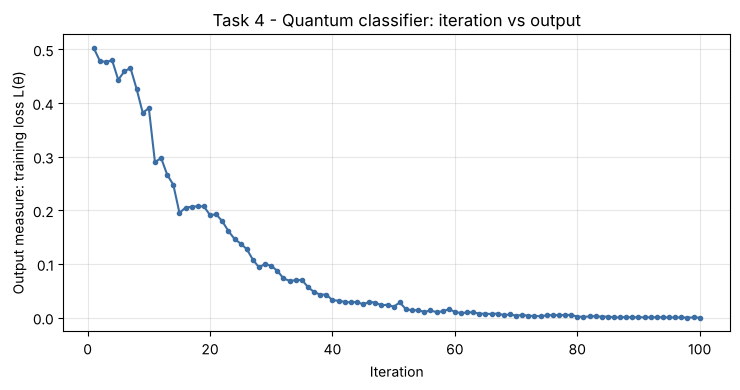

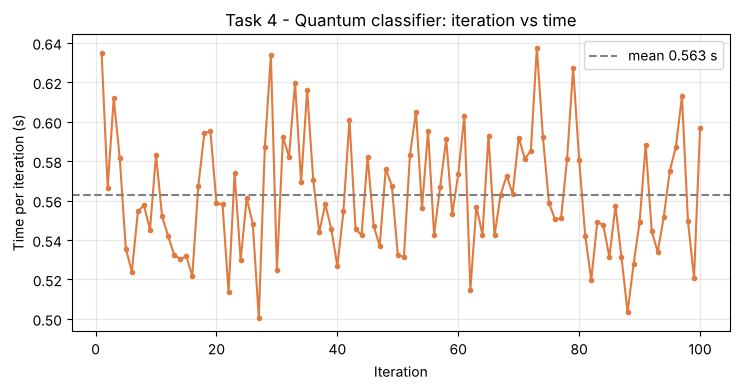

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(hist_quantum["iteration"], hist_quantum["output"], marker=".", color="#3b6ea5")
ax.set_xlabel("Iteration"); ax.set_ylabel("Output measure: training loss L(θ)")
ax.set_title("Task 4 - Quantum classifier: iteration vs output")
ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(RESULTS / "task4_iteration_vs_output.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(hist_quantum["iteration"], hist_quantum["time_s"], marker=".", color="#e07a3f")
ax.axhline(hist_quantum["time_s"].mean(), ls="--", color="grey", label=f"mean {hist_quantum['time_s'].mean():.3f} s")
ax.set_xlabel("Iteration"); ax.set_ylabel("Time per iteration (s)")
ax.set_title("Task 4 - Quantum classifier: iteration vs time")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(RESULTS / "task4_iteration_vs_time.png", dpi=200); plt.show()

## 8. Local-A: same circuit, **no quantum computer** (exact NumPy simulation)

We wrote a tiny state-vector simulator. A 4-qubit state is a vector of $2^4 = 16$ complex amplitudes. Each gate is applied as a matrix on the right qubit. Instead of sampling 1000 shots we compute $P(q_3=1)$ **exactly**, so there is no shot noise.

In [13]:
I2 = np.eye(2)
X_GATE = np.array([[0, 1], [1, 0]], dtype=complex)

def ry_matrix(theta):
    """R_y(theta) = [[cos t/2, -sin t/2], [sin t/2, cos t/2]]."""
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def apply_1q(state, gate, q, n):
    """Apply a 2x2 gate to qubit q of an n-qubit state (qubit 0 = least significant bit)."""
    psi = state.reshape([2] * n)                 # one axis per qubit; axis 0 = qubit n-1
    axis = n - 1 - q
    psi = np.moveaxis(np.tensordot(gate, psi, axes=([1], [axis])), 0, axis)
    return psi.reshape(-1)

def apply_cx(state, control, target, n):
    """CNOT: swap the amplitudes of target 0/1 where control = 1."""
    psi = state.reshape([2] * n).copy()
    idx = [slice(None)] * n
    idx[n - 1 - control] = 1                     # only where the control qubit is 1
    sub = psi[tuple(idx)]
    t_axis = (n - 1 - target) - (1 if (n - 1 - target) > (n - 1 - control) else 0)
    psi[tuple(idx)] = np.flip(sub, axis=t_axis)  # flip the target qubit
    return psi.reshape(-1)

def local_exact_predict(x, image):
    """Same circuit as create_circuit, simulated exactly. Returns P(q3 = 1)."""
    n = len(image)
    state = np.zeros(2 ** n, dtype=complex); state[0] = 1           # |0000>
    for i in range(n):
        if image[i] > 0.5:
            state = apply_1q(state, X_GATE, i, n)                    # input encoding
    pairs = []; generate_pairs(pairs, 0, n - 1)
    for b, (i, j) in enumerate(pairs):
        state = apply_1q(state, ry_matrix(x[2 * b]), i, n)          # RY on first qubit of the block
        state = apply_1q(state, ry_matrix(x[2 * b + 1]), j, n)      # RY on second qubit of the block
        state = apply_cx(state, i, j, n)                             # CNOT
    probs = np.abs(state) ** 2
    return float(sum(p for k, p in enumerate(probs) if (k >> (n - 1)) & 1))   # bit of the last qubit

# Correctness check against Qiskit's exact simulator for random angles
from qiskit.quantum_info import Statevector
test_angles = np.random.default_rng(1).uniform(-3, 3, n_parameters)
qc_check = qiskit.qasm2.loads(create_circuit(dataset[1], test_angles)).remove_final_measurements(inplace=False)
p_qiskit = Statevector(qc_check).probabilities([3])[1]
print(f"Our simulator: {local_exact_predict(test_angles, dataset[1]):.6f}   Qiskit: {p_qiskit:.6f}")

Our simulator: 0.500625   Qiskit: 0.500625


In [14]:
f_localA = lambda x: np.mean([abs(local_exact_predict(x, img) - lab) for img, lab in zip(training, training_labels)])
np.random.seed(SEED)                                     # same random +/-1 sequence as the quantum run
_ = np.pi * np.random.randn(n_parameters)                # skip x0 draw so the SPSA deltas match
t_start = time.perf_counter()
x_localA, hist_localA = spsa(f_localA, x0, a=1, c=0.5, alpha=0.602, gamma=0.101, maxiter=MAXITER)
total_localA = time.perf_counter() - t_start
hist_localA.to_csv(RESULTS / "task4_localA_iterations.csv", index=False)
print(f"Local-A total time {total_localA:.3f} s, final loss {hist_localA['output'].iloc[-1]:.4f}")

Local-A total time 0.163 s, final loss 0.0003


## 9. Local-B: **no quantum circuit at all** (classical logistic regression)

The quantum circuit is replaced by $\hat y = \sigma(\mathbf w\cdot\mathbf x + b)$ with 4 weights and 1 bias (5 parameters, close to the circuit's 6). It uses the same loss and the same SPSA optimiser, so only the model changes.

In [15]:
def classical_predict(params, image):
    w, b = params[:4], params[4]
    return float(1 / (1 + np.exp(-(np.dot(w, image) + b))))   # sigmoid output between 0 and 1

f_localB = lambda p: np.mean([abs(classical_predict(p, img) - lab) for img, lab in zip(training, training_labels)])
np.random.seed(SEED)
p0 = np.random.randn(5)
t_start = time.perf_counter()
p_localB, hist_localB = spsa(f_localB, p0, a=1, c=0.5, alpha=0.602, gamma=0.101, maxiter=MAXITER)
total_localB = time.perf_counter() - t_start
hist_localB.to_csv(RESULTS / "task4_localB_iterations.csv", index=False)
print(f"Local-B total time {total_localB:.3f} s, final loss {hist_localB['output'].iloc[-1]:.4f}")
print("weights:", np.round(p_localB[:4], 2), "bias:", round(p_localB[4], 2))

Local-B total time 0.007 s, final loss 0.2961
weights: [-1.12 -2.12  0.34 -0.01] bias: 0.44


## 9b. Local-C: classical model **with non-linear features** (fair classical baseline)

Local-B fails because the data is not linearly separable. A standard classical fix is to add **pairwise products** of pixels (degree-2 polynomial features), giving 4 + 6 = 10 inputs and 11 parameters. Same loss, same SPSA optimiser.

In [16]:
from itertools import combinations
PAIRS = list(combinations(range(4), 2))                    # (0,1),(0,2),...,(2,3)

def poly_features(image):
    return np.concatenate([image, [image[i] * image[j] for i, j in PAIRS]])   # 4 pixels + 6 products

def poly_predict(params, image):
    z = np.dot(params[:-1], poly_features(image)) + params[-1]
    return float(1 / (1 + np.exp(-z)))

f_localC = lambda p: np.mean([abs(poly_predict(p, img) - lab) for img, lab in zip(training, training_labels)])
np.random.seed(SEED)
q0 = np.random.randn(len(PAIRS) + 5)
t_start = time.perf_counter()
p_localC, hist_localC = spsa(f_localC, q0, a=1, c=0.5, alpha=0.602, gamma=0.101, maxiter=MAXITER)
total_localC = time.perf_counter() - t_start
hist_localC.to_csv(RESULTS / "task4_localC_iterations.csv", index=False)
print(f"Local-C total time {total_localC:.3f} s, final loss {hist_localC['output'].iloc[-1]:.4f}")

Local-C total time 0.034 s, final loss 0.2057


## 10. Comparison: efficiency and effectiveness

In [17]:
# effectiveness is measured with the exact model output, so shot noise does not hide the real accuracy
rows = []
for name, hist, total, x, exact_pred in [
        ("Quantum circuit (" + ("Quokka" if USE_QUOKKA else "local sim, 1000 shots") + ")", hist_quantum, total_quantum, x_quantum, local_exact_predict),
        ("Local-A: same circuit, exact NumPy", hist_localA, total_localA, x_localA, local_exact_predict),
        ("Local-B: classical logistic regression", hist_localB, total_localB, p_localB, classical_predict),
        ("Local-C: classical + pairwise features", hist_localC, total_localC, p_localC, poly_predict)]:
    rows.append({
        "Version": name,
        "Total time (s)": round(total, 3),
        "Mean time / iteration (s)": round(hist["time_s"].mean(), 5),
        "Circuit runs": calls_quantum if hist is hist_quantum else 0,
        "Final loss (monitored)": round(hist["output"].iloc[-1], 4),
        "Best loss": round(hist["output"].min(), 4),
        "Train accuracy": accuracy(exact_pred, x, training, training_labels),
        "Test accuracy": accuracy(exact_pred, x, test, test_labels),
        "All 4 images": accuracy(exact_pred, x, dataset, labels),
    })
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(RESULTS / "task4_comparison.csv", index=False)
speed = comparison.loc[0, "Mean time / iteration (s)"] / comparison.loc[1, "Mean time / iteration (s)"]
print(f"Local-A is about {speed:,.0f} times faster per iteration than the shot-based quantum run.")

,Version,Total time (s),Mean time / iteration (s),Circuit runs,Final loss (monitored),Best loss,Train accuracy,Test accuracy,All 4 images
0,"Quantum circuit (local sim, 1000 shots)",84.636,0.56269,900,0.0000,0.0000,1.0,1.0,1.00
1,"Local-A: same circuit, exact NumPy",0.163,0.00108,0,0.0003,0.0003,1.0,1.0,1.00
2,Local-B: classical logistic regression,0.007,0.00005,0,0.2961,0.2961,1.0,0.0,0.75
3,Local-C: classical + pairwise features,0.034,0.00023,0,0.2057,0.2057,1.0,0.0,0.75


Local-A is about 521 times faster per iteration than the shot-based quantum run.


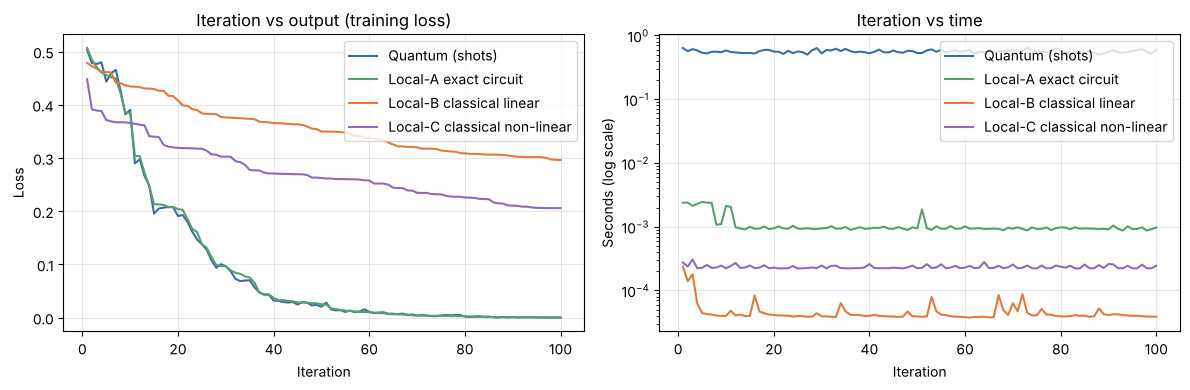

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, lab, col in [(hist_quantum, "Quantum (shots)", "#3b6ea5"), (hist_localA, "Local-A exact circuit", "#5a9e6f"),
                       (hist_localB, "Local-B classical linear", "#e07a3f"), (hist_localC, "Local-C classical non-linear", "#8e6bb8")]:
    axes[0].plot(hist["iteration"], hist["output"], label=lab, color=col)
    axes[1].plot(hist["iteration"], hist["time_s"], label=lab, color=col)
axes[0].set_title("Iteration vs output (training loss)"); axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Loss")
axes[1].set_title("Iteration vs time"); axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Seconds (log scale)")
axes[1].set_yscale("log")
for ax in axes: ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / "task4_comparison_plots.png", dpi=200); plt.show()

In [19]:
# final predictions for every image (exact output of each trained model)
pred = pd.DataFrame({
    "image": [str(img.astype(int)) for img in dataset],
    "label": labels.astype(int),
    "used for": ["train" if i in selected_indices else "test" for i in range(len(dataset))],
    "Quantum P(bar)": [round(local_exact_predict(x_quantum, img), 3) for img in dataset],
    "Local-A P(bar)": [round(local_exact_predict(x_localA, img), 3) for img in dataset],
    "Local-B P(bar)": [round(classical_predict(p_localB, img), 3) for img in dataset],
    "Local-C P(bar)": [round(poly_predict(p_localC, img), 3) for img in dataset],
})
display(pred); pred.to_csv(RESULTS / "task4_predictions.csv", index=False)
summary = {"source": SOURCE, "shots": SHOTS, "maxiter": MAXITER, "seed": SEED,
           "quantum_total_s": total_quantum, "localA_total_s": total_localA, "localB_total_s": total_localB, "localC_total_s": total_localC,
           "circuit_runs": calls_quantum}
_ = (RESULTS / "task4_run_info.json").write_text(json.dumps(summary, indent=2))

,image,label,used for,Quantum P(bar),Local-A P(bar),Local-B P(bar),Local-C P(bar)
0,[1 0 1 0],0,train,0.0,0.0,0.415,0.166
1,[0 1 0 1],0,train,0.0,0.0,0.156,0.105
2,[1 1 0 0],1,test,1.0,1.0,0.057,0.171
3,[0 0 1 1],1,train,1.0,1.0,0.683,0.654


## 11. Conclusion (details in the group report)

* **Input:** the image pixels enter through X gates (basis encoding) in `create_circuit`. The six RY angles are the trainable weights, and qubit 3 is the output.
* **Monitoring:** the loss falls over the iterations, but noisily, because every loss value is itself estimated from finite shots.
* **Efficiency:** removing the quantum computer (Local-A) makes each iteration hundreds to thousands of times faster, because one exact 16-amplitude calculation replaces thousands of shots and (on Quokka) network round trips.
* **Effectiveness:** the data is XOR-like, so a linear classical model cannot separate it. The 6-angle circuit can, because the CNOTs make its output a non-linear function of the pixels. A classical model with non-linear features is the fair comparison. With one test image the test score is weak evidence, and a quantum advantage is not expected at this size.